In [8]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from torchvision import models, transforms

In [9]:
device = torch.device("cpu")

model = models.resnet18(weights=None)

num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Linear(num_features,256),
    nn.ReLU(),
    nn.Dropout(0.4),

    nn.Linear(256,128),
    nn.ReLU(),

    nn.Linear(128,2)
)

model.load_state_dict(
    torch.load(
        "best_bp_model.pth",
        map_location=device
    )
)

model.eval()

print("Model Loaded Successfully")

Model Loaded Successfully


In [10]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

In [11]:
import os

print(os.getcwd())

c:\Users\diksh\OneDrive\Desktop\VT_Project


In [12]:
import os

files = os.listdir("scalograms_final")

print("Total Images:", len(files))

print(files[:10])

Total Images: 3153
['p10020306_83404654_83404654_0005_0.png', 'p10020306_83404654_83404654_0005_1.png', 'p10020306_83404654_83404654_0005_2.png', 'p10020306_83404654_83404654_0005_3.png', 'p10020306_83404654_83404654_0005_4.png', 'p10020306_83404654_83404654_0005_5.png', 'p10020306_83404654_83404654_0006_0.png', 'p10020306_83404654_83404654_0006_1.png', 'p10020306_83404654_83404654_0006_2.png', 'p10020306_83404654_83404654_0006_3.png']


In [13]:
image_path = "scalograms_final/p10020306_83404654_83404654_0005_0.png"

image = Image.open(image_path).convert("RGB")

input_tensor = transform(image).unsqueeze(0)

print(input_tensor.shape)

torch.Size([1, 3, 224, 224])


In [14]:
feature_maps = None
gradients = None

def forward_hook(module, input, output):
    global feature_maps
    feature_maps = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

In [15]:
target_layer = model.layer4[-1].conv2

target_layer.register_forward_hook(forward_hook)

target_layer.register_full_backward_hook(backward_hook)

print("Hooks Registered Successfully")

Hooks Registered Successfully


In [16]:
output = model(input_tensor)

print(output)

target = output[0,0]      # SBP prediction

model.zero_grad()

target.backward()

tensor([[74.3798, 32.2647]], grad_fn=<AddmmBackward0>)


In [17]:
weights = gradients.mean(dim=(2,3), keepdim=True)

cam = (weights * feature_maps).sum(dim=1)

cam = torch.relu(cam)

cam = cam.squeeze().detach().numpy()

cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

print(cam.shape)

(7, 7)


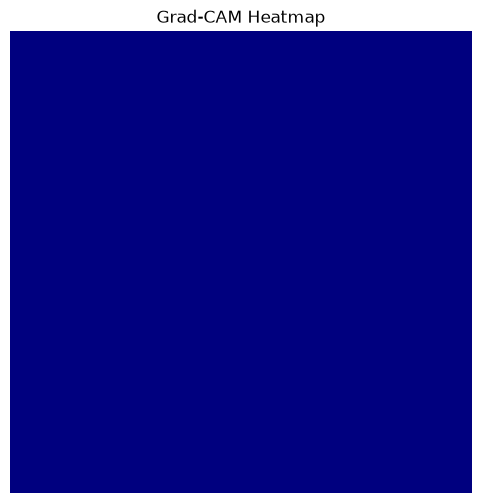

In [18]:
heatmap = cv2.resize(
    cam,
    (224,224)
)

plt.figure(figsize=(6,6))

plt.imshow(
    heatmap,
    cmap="jet"
)

plt.axis("off")

plt.title("Grad-CAM Heatmap")

plt.show()

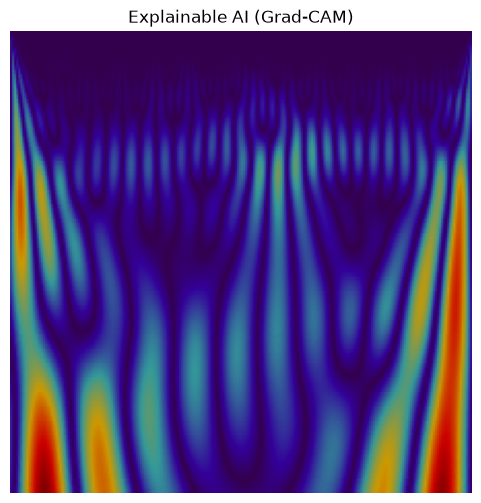

In [19]:
original = np.array(image)

heatmap = np.uint8(255 * heatmap)

heatmap = cv2.applyColorMap(
    heatmap,
    cv2.COLORMAP_JET
)

overlay = cv2.addWeighted(
    original,
    0.6,
    heatmap,
    0.4,
    0
)

plt.figure(figsize=(6,6))

plt.imshow(overlay)

plt.axis("off")

plt.title("Explainable AI (Grad-CAM)")

plt.show()

# ============================================
# Explainable AI (Grad-CAM)
# ============================================

In [20]:
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms

In [21]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

In [22]:
import os

image_name = os.listdir("scalograms_final")[0]

image_path = os.path.join(
    "scalograms_final",
    image_name
)

print(image_path)

scalograms_final\p10020306_83404654_83404654_0005_0.png


In [23]:
image = Image.open(image_path).convert("RGB")

input_tensor = transform(image).unsqueeze(0)

print(input_tensor.shape)

torch.Size([1, 3, 224, 224])


In [24]:
target_layer = model.layer4[-1]

activations = None
gradients = None

def forward_hook(module,input,output):
    global activations
    activations = output.detach()

def backward_hook(module,grad_in,grad_out):
    global gradients
    gradients = grad_out[0].detach()

forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

In [26]:
model.eval()

input_tensor = input_tensor.to(device)

output = model(input_tensor)

print("Prediction:", output)

model.zero_grad()

score = output[0].sum()

score.backward()

Prediction: tensor([[74.3798, 32.2647]], grad_fn=<AddmmBackward0>)


In [27]:
weights = gradients.mean(dim=(2,3), keepdim=True)

cam = (weights * activations).sum(dim=1)

cam = torch.relu(cam)

cam = cam.squeeze().cpu().numpy()

cam = cv2.resize(cam, (224,224))

cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

print(cam.shape)

(224, 224)


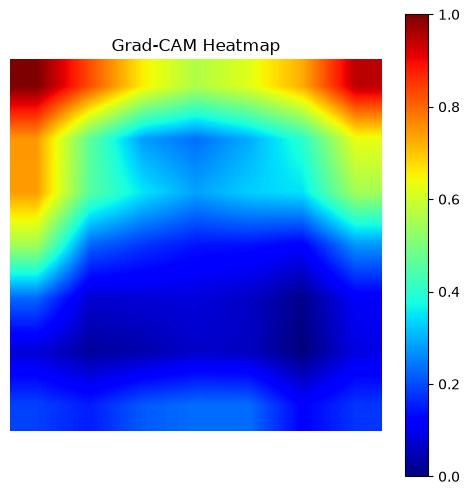

In [28]:
plt.figure(figsize=(6,6))

plt.imshow(
    cam,
    cmap="jet"
)

plt.colorbar()

plt.title("Grad-CAM Heatmap")

plt.axis("off")

plt.show()

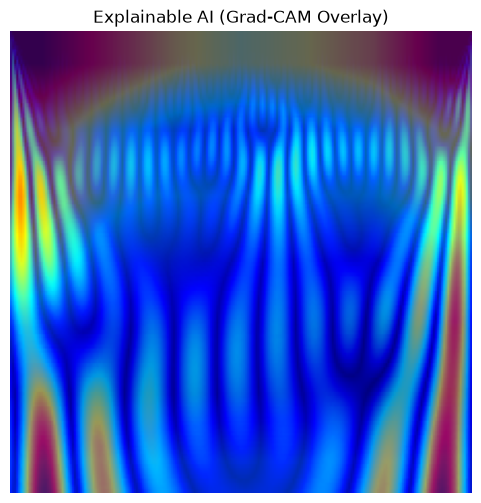

In [29]:
original = np.array(image)

heatmap = cv2.applyColorMap(
    np.uint8(255 * cam),
    cv2.COLORMAP_JET
)

heatmap = cv2.cvtColor(
    heatmap,
    cv2.COLOR_BGR2RGB
)

overlay = cv2.addWeighted(
    original,
    0.6,
    heatmap,
    0.4,
    0
)

plt.figure(figsize=(6,6))

plt.imshow(overlay)

plt.title("Explainable AI (Grad-CAM Overlay)")

plt.axis("off")

plt.show()

In [30]:
plt.figure(figsize=(6,6))

plt.imshow(overlay)

plt.axis("off")

plt.savefig(
    "gradcam_result.png",
    bbox_inches="tight",
    pad_inches=0
)

plt.close()

print("Grad-CAM saved successfully!")

Grad-CAM saved successfully!
